# About this notebook

English edition of the original EDA. The Telco records are a proxy for a cloud-subscription retention problem; they are not Azure customer records. The loader uses the supplied cleaned snapshot to reconstruct the initial 21-column source view, including the 11 missing TotalCharges values.


In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt

In [2]:
from pathlib import Path
import sys
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents]
            if (p / "src" / "project_paths.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from project_paths import load_telco_source, load_support_source, output_dir
OUT = output_dir("data")

# Data is loaded from the included working copy in the next loading cell.


# Telco Customer Churn: Exploratory Analysis

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

df = load_telco_source()
print("Dataset loaded:", df.shape)
df.head()


Dataset loaded: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Basic data checks

In [4]:

display(df.head())


print(df.info())

print(df.shape)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Convert data types and check quality

In [5]:

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Check missing values and duplicates

print(df.isnull().sum())


print(df.duplicated().sum())

# Encode churn as 0/1
df["Churn_binary"] = df["Churn"].map({"Yes": 1, "No": 0})

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
0


## Churn distribution

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


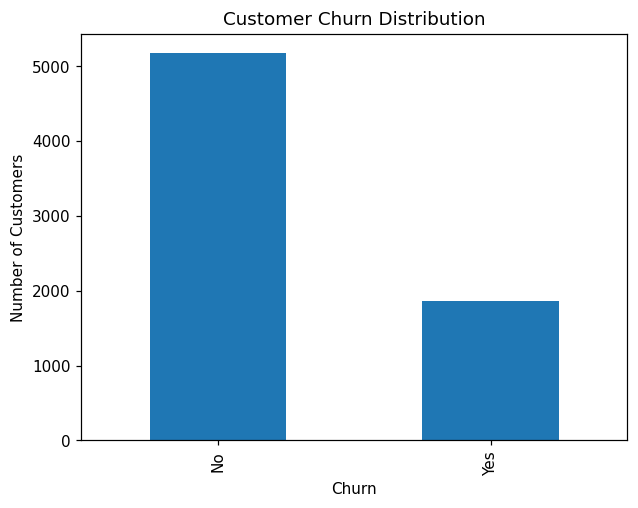

In [6]:

print(df["Churn"].value_counts())


print(df["Churn"].value_counts(normalize=True))

df["Churn"].value_counts().plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

## Numeric variables: tenure, monthly charges, and total charges


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


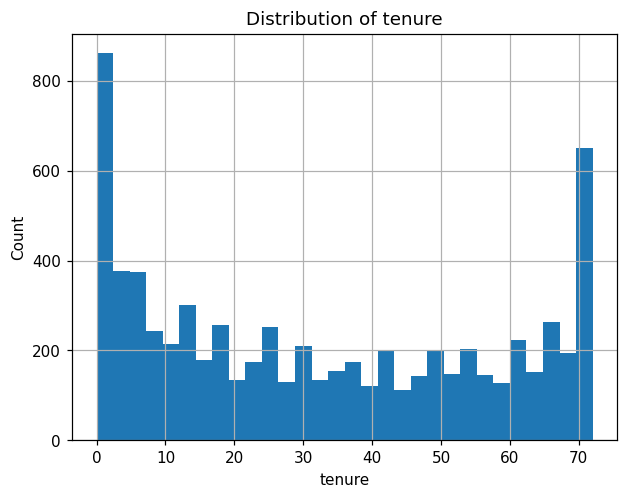

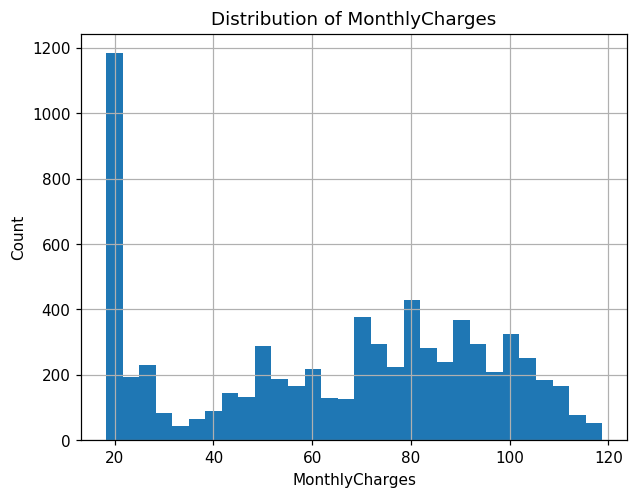

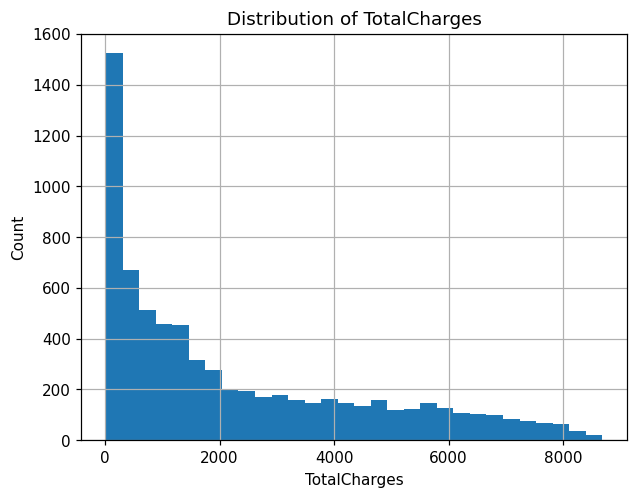

In [7]:
cols = ["tenure", "MonthlyCharges", "TotalCharges"]

display(df[cols].describe())
for col in cols:
    plt.figure()
    df[col].hist(bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [8]:
display(df.groupby("Churn")[cols].mean())

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2555.344141
Yes,17.979133,74.441332,1531.796094


## Categorical variables


In [9]:
categorical_cols = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "TechSupport",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

In [10]:
for col in categorical_cols:
    print(f"\n{col} distribution:")
    print(df[col].value_counts())
for col in categorical_cols:
    churn_rate = df.groupby(col)["Churn_binary"].mean().sort_values(ascending=False)
    print(f"\nChurn rate by {col}:")
    print(churn_rate)


gender distribution:
gender
Male      3555
Female    3488
Name: count, dtype: int64

SeniorCitizen distribution:
SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64

Partner distribution:
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents distribution:
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService distribution:
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines distribution:
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService distribution:
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity distribution:
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup distribution:
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: coun

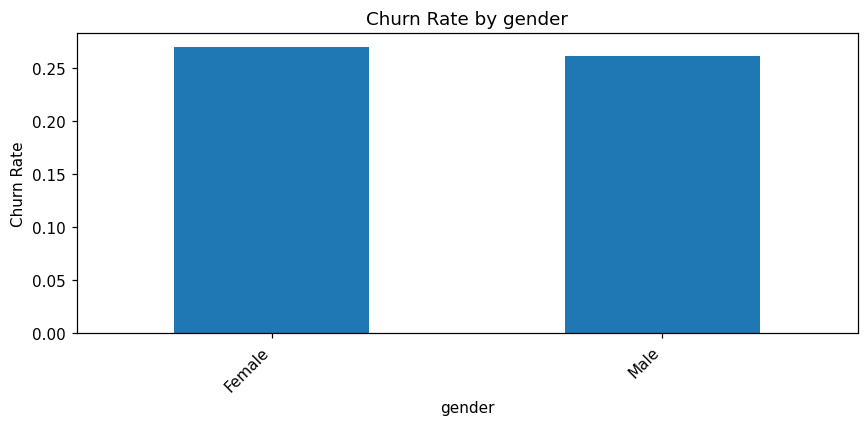

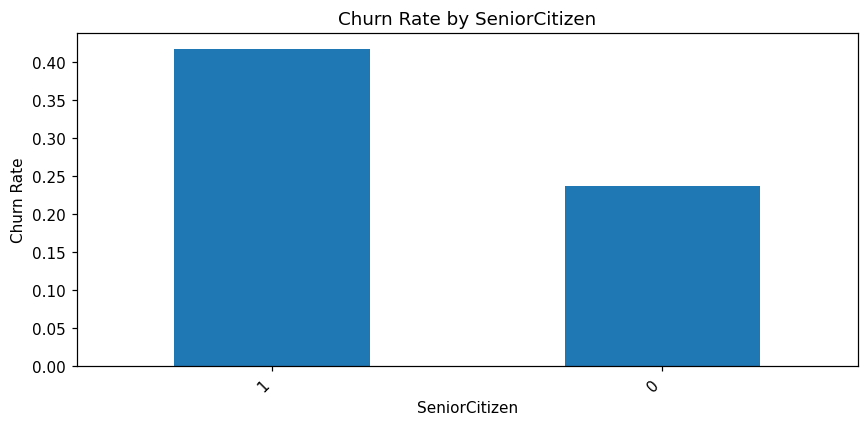

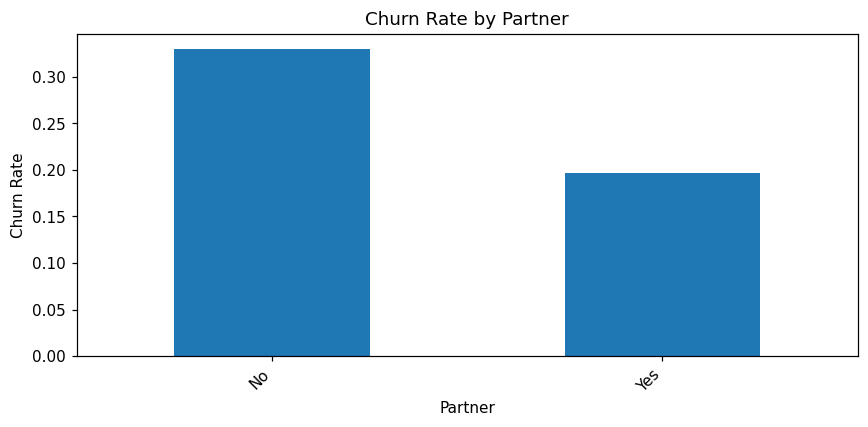

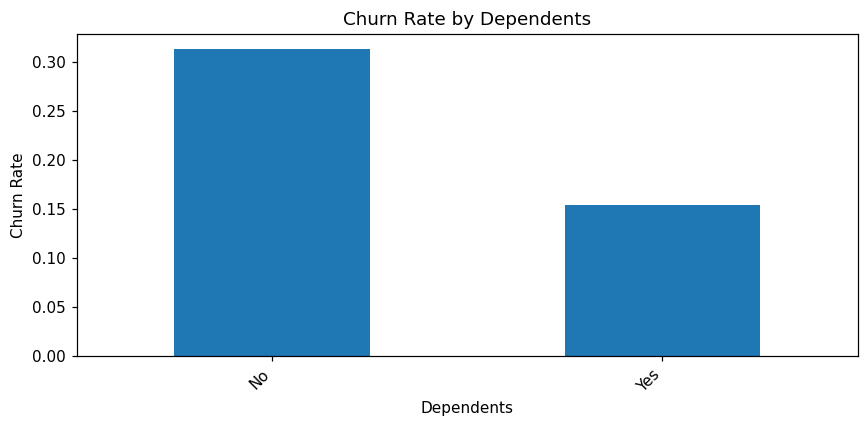

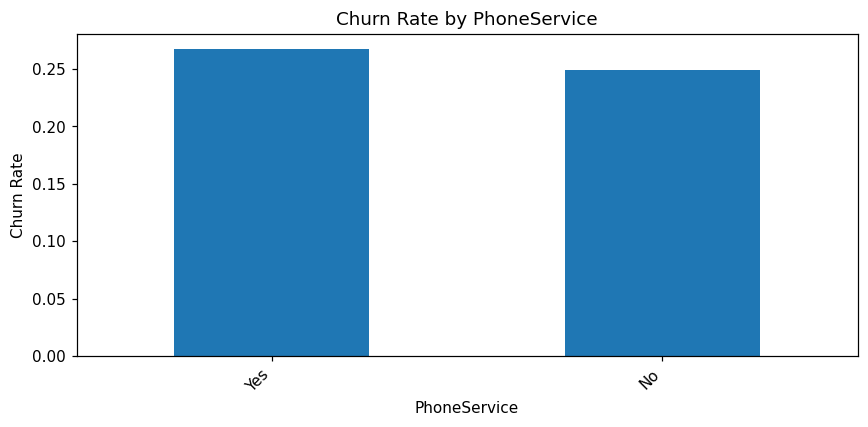

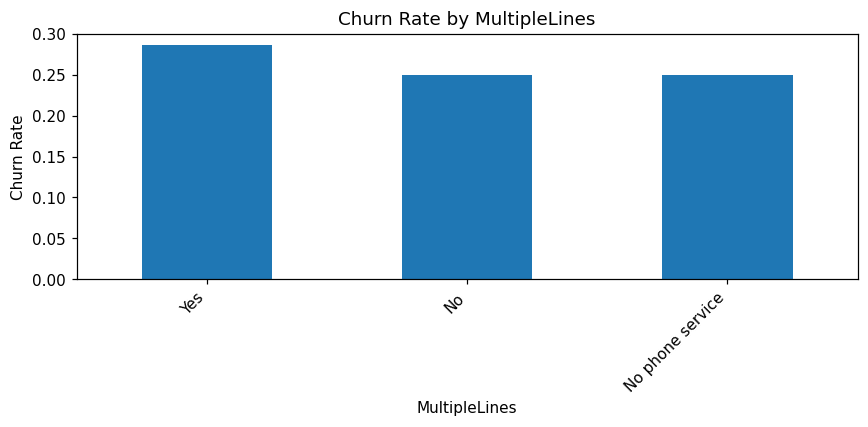

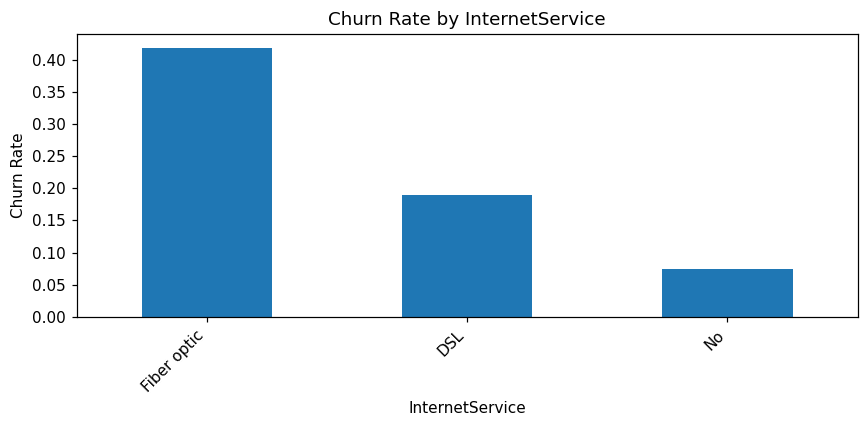

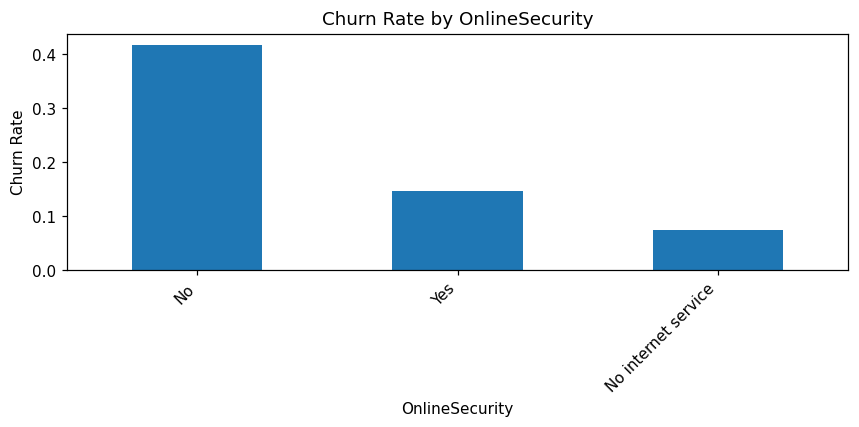

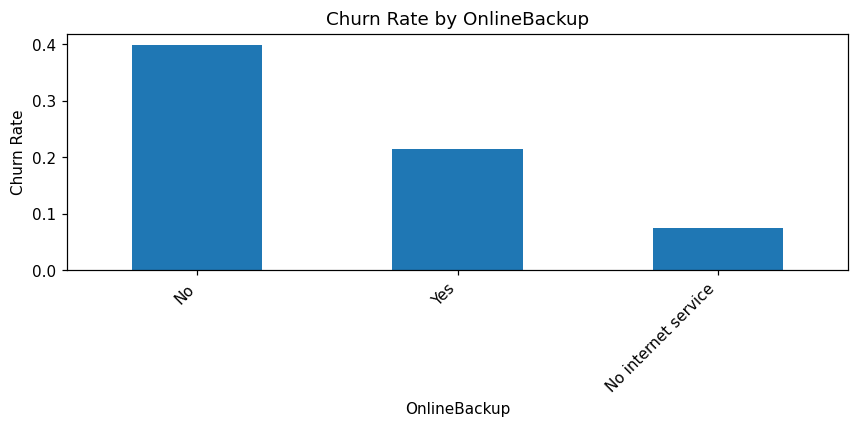

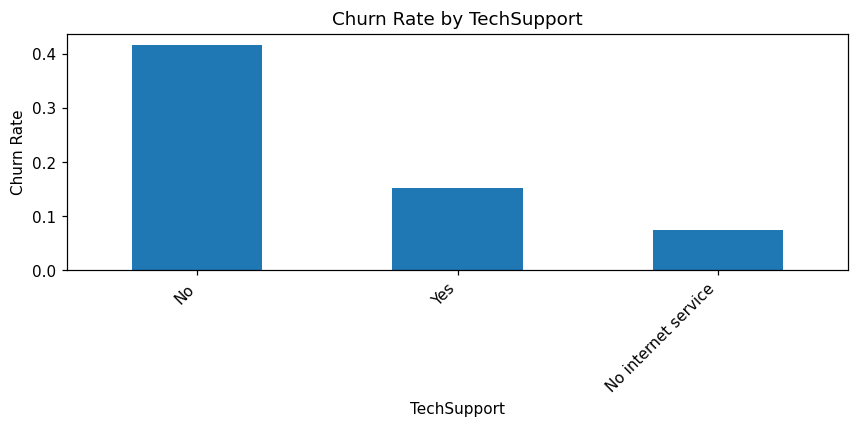

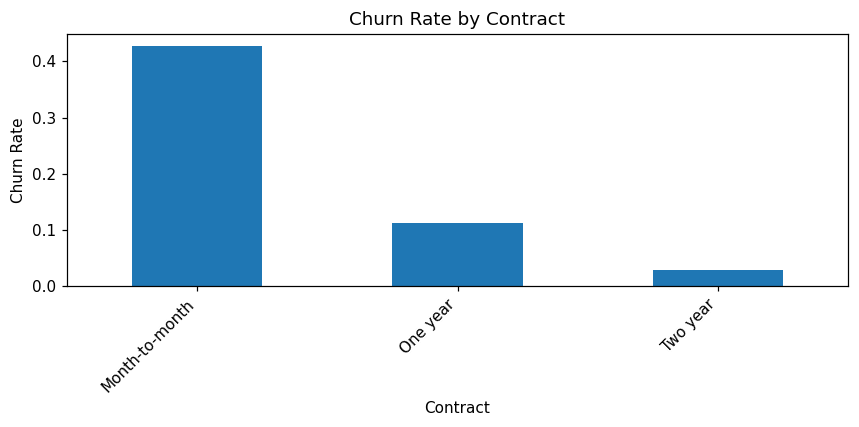

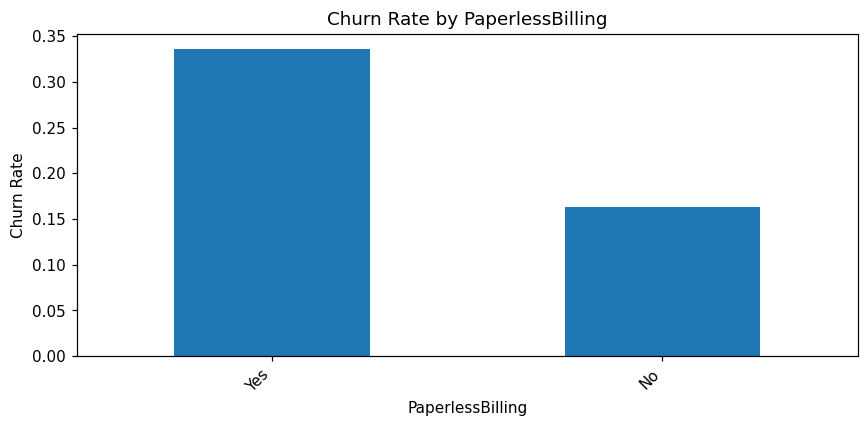

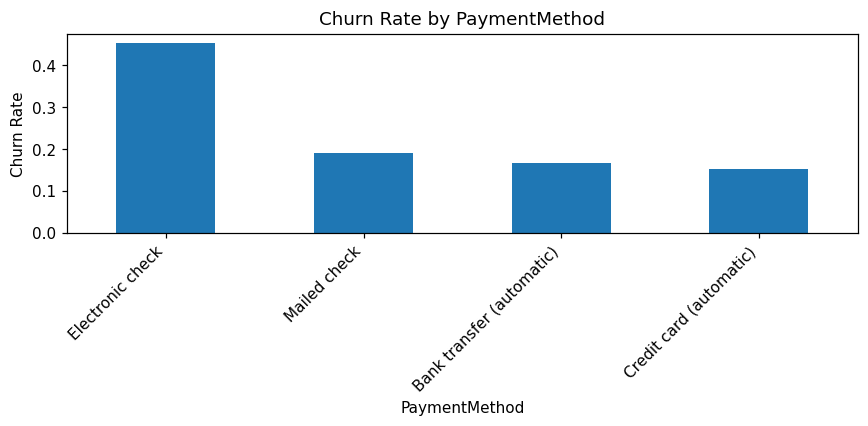

In [11]:
for col in categorical_cols:
    churn_rate = df.groupby(col)["Churn_binary"].mean().sort_values(ascending=False)

    plt.figure(figsize=(8, 4))
    churn_rate.plot(kind="bar")
    plt.title(f"Churn Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Churn Rate")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## Churn by tenure group

In [12]:
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
)

display(df.groupby("tenure_group", observed=False)["Churn_binary"].mean())

tenure_group
0-12 months     0.474382
13-24 months    0.287109
25-48 months    0.203890
49-72 months    0.095132
Name: Churn_binary, dtype: float64

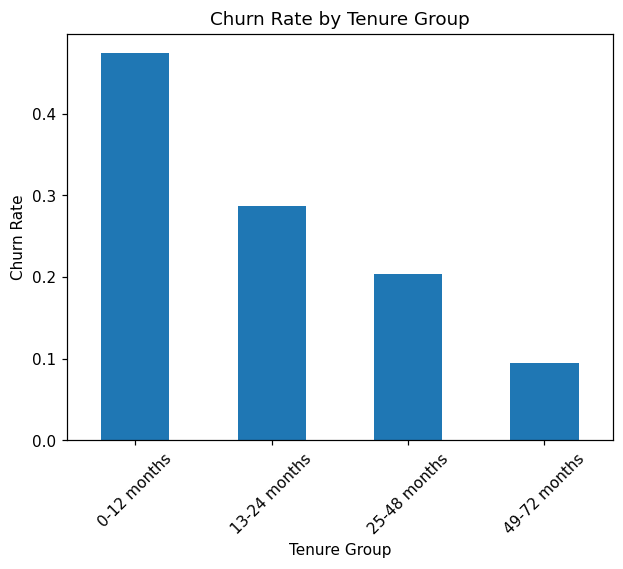

In [13]:
df.groupby("tenure_group", observed=False)["Churn_binary"].mean().plot(kind="bar")
plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate")
plt.xticks(rotation=45)
plt.show()

## Churn by monthly charge group

In [14]:
df["monthly_charge_group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 90, 120],
    labels=["Low", "Medium", "High", "Very High"]
)


display(df.groupby("monthly_charge_group", observed=False)["Churn_binary"].mean())

monthly_charge_group
Low          0.108934
Medium       0.239420
High         0.377983
Very High    0.327775
Name: Churn_binary, dtype: float64

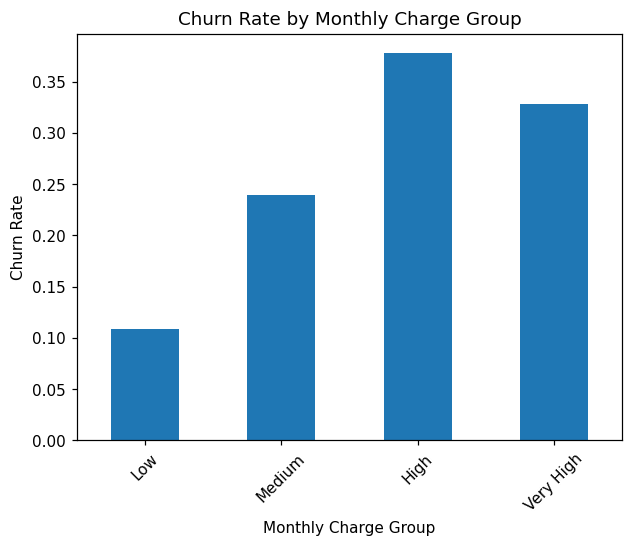

In [15]:
df.groupby("monthly_charge_group", observed=False)["Churn_binary"].mean().plot(kind="bar")
plt.title("Churn Rate by Monthly Charge Group")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Churn Rate")
plt.xticks(rotation=45)
plt.show()

## Combined-variable analysis

In [16]:
pivot_contract_support = df.pivot_table(
    values="Churn_binary",
    index="Contract",
    columns="TechSupport",
    aggfunc="mean"
)


display(pivot_contract_support)

TechSupport,No,No internet service,Yes
Contract,,,
Month-to-month,0.503731,0.188931,0.307004
One year,0.147217,0.024725,0.135870
Two year,0.059322,0.007837,0.035323


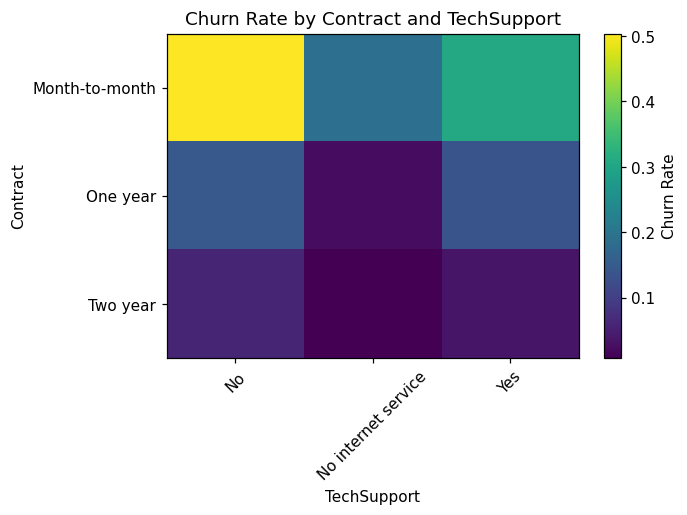

In [17]:
plt.imshow(pivot_contract_support, aspect="auto")
plt.colorbar(label="Churn Rate")
plt.xticks(range(len(pivot_contract_support.columns)), pivot_contract_support.columns, rotation=45)
plt.yticks(range(len(pivot_contract_support.index)), pivot_contract_support.index)
plt.title("Churn Rate by Contract and TechSupport")
plt.xlabel("TechSupport")
plt.ylabel("Contract")
plt.tight_layout()
plt.show()

PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
Contract,,,,
Month-to-month,0.341256,0.327808,0.537297,0.315789
One year,0.097187,0.103015,0.184438,0.068249
Two year,0.033688,0.022375,0.077381,0.007853


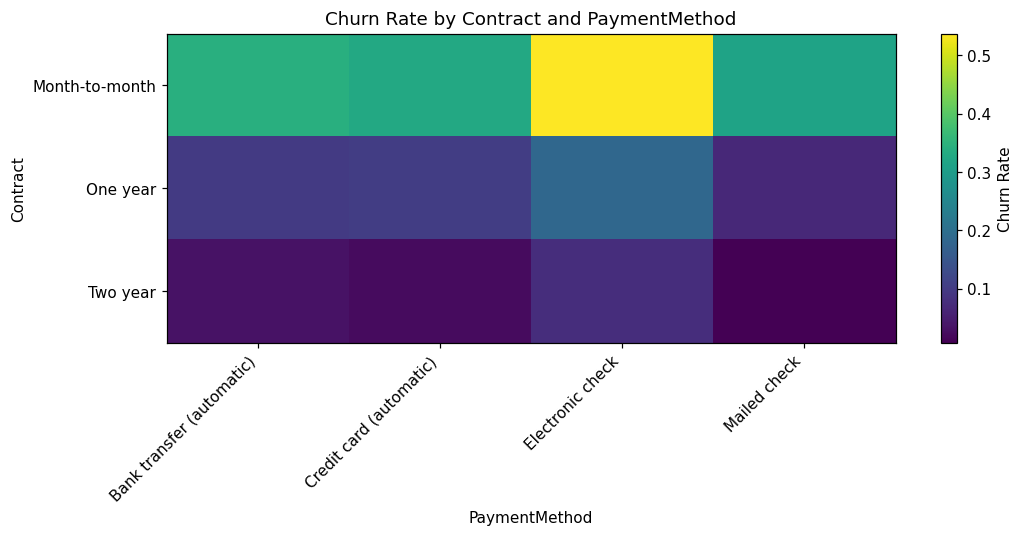

In [18]:
pivot_contract_payment = df.pivot_table(
    values="Churn_binary",
    index="Contract",
    columns="PaymentMethod",
    aggfunc="mean"
)


display(pivot_contract_payment)

plt.figure(figsize=(10, 5))
plt.imshow(pivot_contract_payment, aspect="auto")
plt.colorbar(label="Churn Rate")
plt.xticks(range(len(pivot_contract_payment.columns)), pivot_contract_payment.columns, rotation=45, ha="right")
plt.yticks(range(len(pivot_contract_payment.index)), pivot_contract_payment.index)
plt.title("Churn Rate by Contract and PaymentMethod")
plt.xlabel("PaymentMethod")
plt.ylabel("Contract")
plt.tight_layout()
plt.show()

## Descriptive ranking by churn-rate gap

,feature,max_churn_rate,min_churn_rate,churn_rate_gap
10,Contract,0.427097,0.028319,0.398778
6,InternetService,0.418928,0.074050,0.344878
7,OnlineSecurity,0.417667,0.074050,0.343617
9,TechSupport,0.416355,0.074050,0.342305
8,OnlineBackup,0.399288,0.074050,0.325238
12,PaymentMethod,0.452854,0.152431,0.300423
1,SeniorCitizen,0.416813,0.236062,0.180751
11,PaperlessBilling,0.335651,0.163301,0.172350
3,Dependents,0.312791,0.154502,0.158289
2,Partner,0.329580,0.196649,0.132931


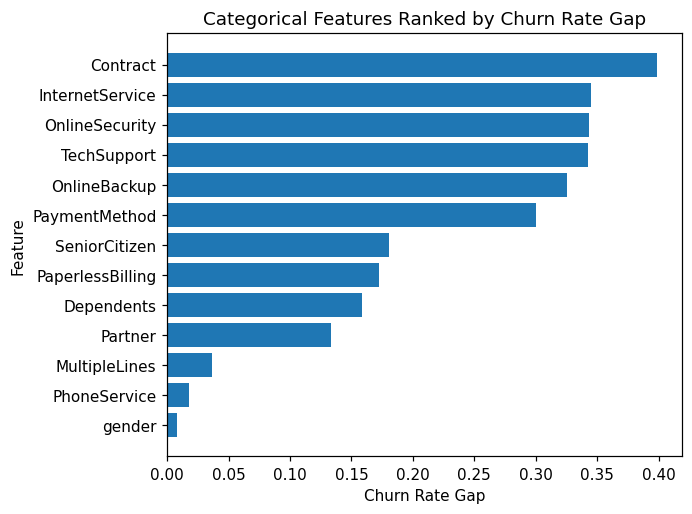

In [19]:
importance_list = []

for col in categorical_cols:
    churn_rates = df.groupby(col)["Churn_binary"].mean()
    gap = churn_rates.max() - churn_rates.min()
    importance_list.append({
        "feature": col,
        "max_churn_rate": churn_rates.max(),
        "min_churn_rate": churn_rates.min(),
        "churn_rate_gap": gap
    })

importance_df = pd.DataFrame(importance_list)
importance_df = importance_df.sort_values(by="churn_rate_gap", ascending=False)


display(importance_df)

plt.barh(importance_df["feature"], importance_df["churn_rate_gap"])
plt.title("Categorical Features Ranked by Churn Rate Gap")
plt.xlabel("Churn Rate Gap")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
importance_df.to_csv(OUT / "feature_churn_rate_gap_ranking.csv", index=False)


## Export data for Power BI

In [20]:
df["high_risk_segment"] = (
    (df["Contract"] == "Month-to-month") &
    (df["TechSupport"] == "No") &
    (df["PaymentMethod"] == "Electronic check")
).map({True: "High Risk Segment", False: "Other Customers"})

df.to_csv(OUT / "telco_powerbi.csv", index=False)

print("Exported telco_powerbi.csv successfully.")

Exported telco_powerbi.csv successfully.
